# AI livestream overlay verification

## What you will build

**Recipe 95 · Advanced · Images + structured state + `Noul`.** Build a verifier for three displayed agent claims: the current game phase, selected action and action status. Compare those claims with authored gameplay frames, then let Python decide whether to retain the overlay or request a human check before any update.

Each [Noul](../../docs/glossary.md#noul) is a true/false proposition returning the probability of true. We ask six independent propositions together: visual support and visual resolvability for each claim. Python owns timestamps, confidence thresholds, contradictions and all simulated recommendations ([S02](https://docs.typesafe.ai/primitives), [S03](https://docs.typesafe.ai/confidence)).

The PNGs depict a fictional game, not captured gameplay. They include readable disagreement, delayed overlays, unrelated scene changes, occluded HUD fields, menus, loading screens, reversed timestamps and unknown claims. Strategy text appears in the overlay, but evaluating strategy quality is outside this example. “Selected action” means the readable game HUD value; a single still cannot prove that the action's real-world effects occurred.

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## Setup and run mode

The [run mode](../../docs/glossary.md#run-mode) says where answers came from. Offline replay is the default. Its [provenance](../../docs/glossary.md#provenance) is synthetic: every answer was authored, including deliberate mistakes. The header appears before any decision call.

Live execution is explicit: install the optional SDK, set `JEV_COOKBOOK_LIVE=1`, `TYPESAFE_API_KEY` and `JEV_COOKBOOK_LIVE_MAX_REQUESTS=26` or higher for retries. The notebook pins `jev-1.14.0` and enables the experimental image header through `images=True`; backend selection changes no question or input ([S09](https://docs.typesafe.ai/images), [S11](https://docs.typesafe.ai/models), [S12](https://typesafe.ai/blog/jev-1-14)). The notebook executor always runs offline. There are 26 distinct episode requests; caching prevents the demos or evaluations from requesting an episode twice.

In [1]:
import json
from pathlib import Path
from time import perf_counter

from matplotlib.figure import Figure
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import accuracy, confusion_matrix, evaluate_outcomes
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import run_record

apply_style()
helpers = load_helpers()
examples = [dict(id=e.id, split=e.split, fields=e.fields) for e in load_inputs()]
gold = load_labels()
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
questions = helpers.build_questions()
offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
selection = " (a selection step, not a reported result)"
run_header("95", "AI livestream overlay verification", backend=backend, n_examples=24)
results, accounting = {}, {}


def decide(example):
    ident = example["id"]
    if ident not in results:
        state, assets = helpers.build_request(example["fields"], Path.cwd())
        start = perf_counter() if backend.mode == "live" else None
        result = backend.decide(state, questions, assets=assets)
        elapsed = perf_counter() - start if start is not None else None
        results[ident] = result
        accounting[ident] = run_record(result, mode=backend.mode, measured_latency_seconds=elapsed)
    return results[ident].answers

Recipe 95: AI livestream overlay verification
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The model and deterministic baseline receive the same raw claims, telemetry cache and timestamp evidence. The visual questions use only the gameplay area: an overlay's own text and a possibly stale telemetry cache cannot corroborate the overlay. The baseline uses exact telemetry/claim equality and ignores pixels, so equal access does not mean equal use of evidence.

Each frame is 512 × 384 pixels. Assets live beside `fixtures/`, and Python replaces local filenames with content-hash references. No label, scenario name, split or synthetic answer enters the model state. A [replay key](../../docs/glossary.md#replay-key) identifies the state, questions and image bytes, so changing a frame invalidates its stored response.

The two pictures below show a transition from combat to rewards while the overlay remains on combat. An ambient light also moves: changed pixels alone say nothing about which claim became false. The difference mask includes both gameplay and overlay regions.

Episodes use distinct authored zone markings. The splits share this small fictional HUD design, so held-out here means held-out authored episodes, not unseen real games or layouts.

In [2]:
demo = {e["id"]: e for e in examples if e["split"] == "demo"}
state, assets = helpers.build_request(demo["d01"]["fields"], Path.cwd())
print(json.dumps(state, indent=2))
print("Assets carry authored PNG bytes; filenames and expected labels are absent from this state.")

{
  "frames_in_supplied_order": [
    {
      "captured_ms": 339500,
      "image": "image:sha256:455aa4cd5471f1207f0299f8f7517823cf668df837c1bf6dd404d4a7419d6fcd"
    },
    {
      "captured_ms": 340000,
      "image": "image:sha256:9d6bc9f6be77480017afb66eabbf1ad48b1feec71709b5d7f5fdf0dd5bc22ad3"
    }
  ],
  "agent_claims": {
    "phase": "combat",
    "action": "collect",
    "status": "ready"
  },
  "game_telemetry": {
    "phase": "rewards",
    "action": "collect",
    "status": "ready"
  },
  "claim_vocabulary": {
    "phase": [
      "combat",
      "loading",
      "map",
      "menu",
      "rewards"
    ],
    "action": [
      "attack",
      "block",
      "choose_route",
      "collect",
      "none"
    ],
    "status": [
      "complete",
      "executing",
      "loading",
      "paused",
      "ready"
    ]
  },
  "overlay_updated_ms": 339750,
  "observed_ms": 340100,
  "legend": "Each authored frame: gameplay above y=272; agent overlay below y=272. The bottom overl

Demo d01: changed pixels=892/196608 (a pipeline check, not a Jev result)


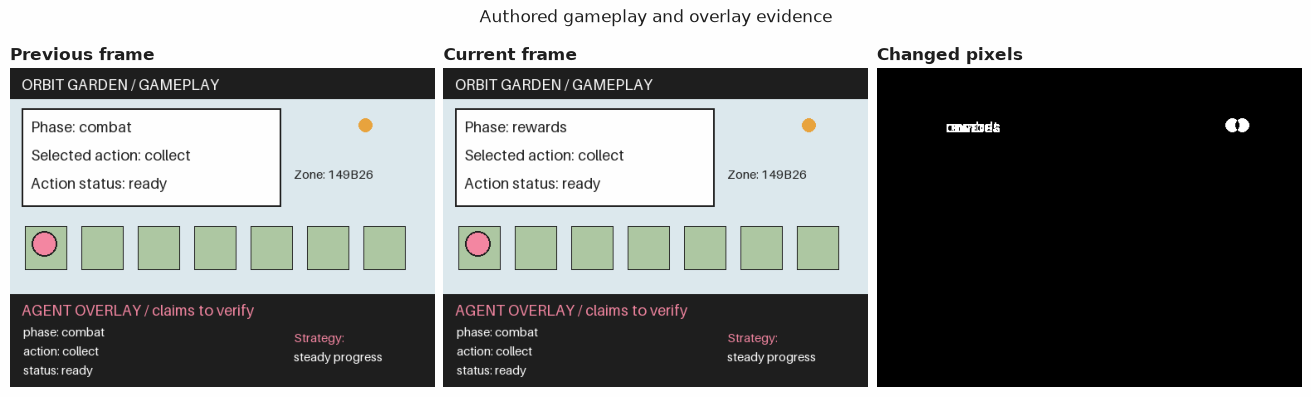

In [3]:
fields = demo["d01"]["fields"]
mask = helpers.pixel_difference(fields, Path.cwd())
print(f"Demo d01: changed pixels={int(mask.sum())}/{mask.size}{check}")
fig = Figure(figsize=(13, 4.2), layout="constrained")
axes = fig.subplots(1, 3)
for ax, frame, title in zip(
    axes[:2], fields["frames"], ("Previous frame", "Current frame"), strict=True
):
    ax.imshow(Image.open(frame["path"]))
    ax.set_title(title)
axes[2].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Changed pixels")
for ax in axes:
    ax.axis("off")
fig.suptitle("Authored gameplay and overlay evidence")
fig

## The questions

“Unsupported” requires readable gameplay that disagrees. “Unresolved” means the evidence cannot settle the claim. A false support proposition alone cannot distinguish them, so each claim has an independent resolvability proposition. Their answers are composed in Python; one answer is never inserted into another question.

Noul has no API confidence field. The cookbook derives certainty as `abs(2*p - 1)` ([S03](https://docs.typesafe.ai/confidence)). A [confidence gate](../../docs/glossary.md#confidence-gate) is a minimum certainty used before accepting a judgment. We also reject exact probability ties, even with a zero gate.

In [4]:
for name, question in questions.items():
    print(f"{name}: {question.instructions}")
    print(json.dumps(dict(question.criteria), indent=2))

phase_resolvable: The gameplay evidence is sufficient to confirm or refute `agent_claims.phase`. Use the final frame's gameplay area, excluding the agent overlay and telemetry. The target is the displayed phase claim `agent_claims.phase`. Judge this proposition independently of the support proposition.
{
  "true": "Readable game indicators establish this field's value.",
  "false": "The relevant HUD is occluded, unreadable, absent, or outside the defined vocabulary. A loading screen alone cannot establish an action or readiness."
}
phase_supported: The gameplay visibly supports `agent_claims.phase`. Use the final frame's gameplay area, excluding the agent overlay and telemetry. The target is the displayed phase claim `agent_claims.phase`. Judge the current displayed game field, not whether the strategy is wise or whether an intended action will happen.
{
  "true": "The readable gameplay field agrees with the agent's stated value.",
  "false": "The gameplay contradicts the claim, or doe

## One answer up close

This unscored demo's overlay says `combat` while the gameplay HUD says `rewards`. Inspect the typed Noul answers before any aggregate. In the committed synthetic run, the numbers below are authored probabilities, not model measurements.

In [5]:
first_answers = decide(demo["d01"])
for name in questions:
    print(name)
    show_answer(first_answers[name])

phase_resolvable
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
phase_supported
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
action_resolvable
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
action_supported
Noul: 0.96 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
status_resolvable
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
status_supported
Noul: 0.96 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


## Python's part

Python reports each claim as `supported`, `unsupported` or `unresolved`. Unknown claim vocabulary, uncertain answers, unreadable evidence and contradictory “supported but unresolvable” answers stay unresolved. [Review](../../docs/glossary.md#review) means a person must decide before an overlay update; it is not an accepted answer. A semantic mismatch event means at least one claim is unsupported, independent of capture age.

Timestamps use one shared monotonic clock, in milliseconds, with no allowed future skew. Python requires exactly two increasing frame timestamps, the current frame no later than observation, and the overlay update no later than that frame. Capture age above 2,000 ms flags `stream_stale`; overlay lag above 3,000 ms flags `overlay_delayed`. Equality is allowed. These fixed example policies are not tuned. Invalid order makes visual claims unresolved, because “current” is ambiguous. A stale but ordered snapshot still has semantic labels, and its freshness flag is reported separately. A frozen picture with renewed timestamps can pass these timestamp checks.

All unresolved, unsupported or stale cases enter an in-memory `ReviewQueue`, leaving `ActionLog` empty. Only fresh, fully supported claims record an unexecuted recommendation to retain the overlay. A negative answer does not authorize a replacement string. No game or streaming API is called.

A [gold label](../../docs/glossary.md#gold-label) is the author's expected answer based on visible evidence. The validation split selects the highest number of answered claims with 100% answered accuracy, among gates 0, 0.5, 0.75 and 0.9; ties choose the lower gate. The gate is then frozen. [Accuracy](../../docs/glossary.md#accuracy) is the fraction of labels that match gold. [Coverage](../../docs/glossary.md#coverage) is the fraction actually answered, and abstention is one minus coverage.

In [6]:
validation = [e for e in examples if e["split"] == "validation"]
validation_answers = {e["id"]: decide(e) for e in validation}
gate, sweep = helpers.select_gate(validation, validation_answers, gold)
for candidate, metric in sweep:
    print(
        f"Validation N={len(validation)} episodes / {metric.n_total} claims; gate={candidate:.2f}; "
        f"answered={metric.n_answered}; accuracy={metric.accuracy:.3f}{selection}{check}"
    )
print(
    f"Frozen gate={gate:.2f}, selected on validation N={len(validation)} episodes{selection}{check}"
)

Validation N=12 episodes / 36 claims; gate=0.00; answered=29; accuracy=0.966 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12 episodes / 36 claims; gate=0.50; answered=28; accuracy=1.000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12 episodes / 36 claims; gate=0.75; answered=28; accuracy=1.000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Validation N=12 episodes / 36 claims; gate=0.90; answered=28; accuracy=1.000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
Frozen gate=0.50, selected on validation N=12 episodes (a selection step, not a reported result) (a pipeline check, not a Jev result)


In [7]:
demo_actions, demo_queue = ActionLog(), ReviewQueue()
for example in demo.values():
    outcome = helpers.route(
        example["id"],
        example["fields"],
        decide(example),
        gate,
        actions=demo_actions,
        queue=demo_queue,
    )
    print(example["id"], outcome)
print("Review notes only; no overlay changed:")
for note in demo_queue.to_dicts():
    print({key: value for key, value in note.items() if key != "answer"})
print("Simulated action entries:", demo_actions.to_dicts())

d01 Outcome(claims={'phase': 'unsupported', 'action': 'supported', 'status': 'supported'}, time_flags=(), semantic_mismatch=True, review=True, recommendation='review evidence before any overlay update')
d02 Outcome(claims={'phase': 'supported', 'action': 'unresolved', 'status': 'supported'}, time_flags=(), semantic_mismatch=False, review=True, recommendation='review evidence before any overlay update')
Review notes only; no overlay changed:
{'id': 0, 'item': {'example': 'd01', 'claims': {'phase': 'unsupported', 'action': 'supported', 'status': 'supported'}, 'time_flags': []}, 'reason': 'phase: visible disagreement; action: readable gameplay agrees; status: readable gameplay agrees', 'step': None, 'status': 'pending', 'resolution': None}
{'id': 1, 'item': {'example': 'd02', 'claims': {'phase': 'supported', 'action': 'unresolved', 'status': 'supported'}, 'time_flags': []}, 'reason': 'phase: readable gameplay agrees; action: support contradicts unresolvable evidence; status: readable game

## Evaluation

Use the frozen gate once on the held-out test split. Each per-claim metric covers 12 episodes; the combined claim matrix covers 36 claims. Three-way accuracy includes correctly unresolved cases. Answered accuracy excludes unresolved predictions, while abstention counts them explicitly. These per-claim results are distinct from whether an entire episode permits a recommendation.

An event is a visually established semantic mismatch at the captured frame. An unresolved-only episode means “no mismatch established,” not agreement; the per-claim abstention and episode review counts retain that distinction. [Precision](../../docs/glossary.md#precision) is the share of flagged events that are true mismatches; [recall](../../docs/glossary.md#recall) is the share of true mismatches flagged. We print true-positive, false-positive and false-negative counts, and an undefined precision remains `nan` if no event is flagged. Freshness or unreadability reviews do not become semantic true positives.

The exact telemetry baseline uses the same input fields and timestamp gate. It can miss a stale cache that agrees with an incorrect overlay, and it can succeed when a synthetic visual answer is wrong. This comparison checks the evaluation plumbing; it provides no evidence about real-world relative performance.

Event accuracy is correct binary event labels divided by all 12 test episodes. Unresolved-only episodes, invalid frame order and stale captures remain in this denominator under the existing policy. No established mismatch is the negative event label; it does not establish that the overlay is correct. Per-claim abstention and episode review are reported separately. Event accuracy therefore differs from precision and recall, whose denominators contain flagged or established-positive events.

In [8]:
test = [e for e in examples if e["split"] == "test"]
test_answers = {e["id"]: decide(e) for e in test}
reports, outcomes, actions, queue = helpers.evaluate(test, test_answers, gold, gate)
for method, report in reports.items():
    for claim, metric in report["claims"].items():
        print(
            f"{method}/{claim}: N={metric['N']}; three-way accuracy={metric['three_way_accuracy']:.3f}; "
            f"answered={metric['answered']}; answered accuracy={metric['answered_accuracy']:.3f}; "
            f"abstention={metric['abstention']:.3f}{check}"
        )
    event = report["event"]
    print(
        f"{method}/semantic event: N={event['N']}; correct={event['correct']}/{event['N']}; "
        f"event accuracy={event['accuracy']:.3f}{check}"
    )
    print(
        f"{method}/semantic event: N={event['N']}; TP={event['tp']}; TN={event['tn']}; "
        f"FP={event['fp']}; FN={event['fn']}; "
        f"precision={event['precision']:.3f}; recall={event['recall']:.3f}{check}"
    )
accepted = [not outcomes[e["id"]].review for e in test]
correct = [outcomes[e["id"]].claims == gold[e["id"]]["claims"] for e in test]
workflow = evaluate_outcomes(accepted, correct)
review_agreement = accuracy(
    [gold[e["id"]]["review"] for e in test], [outcomes[e["id"]].review for e in test]
)
time_agreement = accuracy(
    [tuple(gold[e["id"]]["time_flags"]) for e in test],
    [outcomes[e["id"]].time_flags for e in test],
)
print(
    f"Actual episode policy: N={len(test)}; recommendations={workflow.n_answered}; "
    f"coverage={workflow.coverage:.3f}; accepted accuracy={workflow.accuracy:.3f}; "
    f"review agreement={review_agreement:.3f}; time-flag agreement={time_agreement:.3f}{check}"
)
for example in test:
    outcome = outcomes[example["id"]]
    print(f"{example['id']}: {outcome.claims}; time={outcome.time_flags}; review={outcome.review}")

visual/phase: N=12; three-way accuracy=1.000; answered=10; answered accuracy=1.000; abstention=0.167 (a pipeline check, not a Jev result)
visual/action: N=12; three-way accuracy=0.917; answered=9; answered accuracy=0.889; abstention=0.250 (a pipeline check, not a Jev result)
visual/status: N=12; three-way accuracy=0.917; answered=10; answered accuracy=0.900; abstention=0.167 (a pipeline check, not a Jev result)
visual/semantic event: N=12; TP=4; FP=1; FN=1; precision=0.800; recall=0.800 (a pipeline check, not a Jev result)
exact_baseline/phase: N=12; three-way accuracy=0.917; answered=10; answered accuracy=0.900; abstention=0.167 (a pipeline check, not a Jev result)
exact_baseline/action: N=12; three-way accuracy=0.833; answered=11; answered accuracy=0.818; abstention=0.083 (a pipeline check, not a Jev result)
exact_baseline/status: N=12; three-way accuracy=0.917; answered=11; answered accuracy=0.909; abstention=0.083 (a pipeline check, not a Jev result)
exact_baseline/semantic event: 

Test N=12 episodes / 36 claims; rows=gold, columns=predicted (a pipeline check, not a Jev result)
supported: [23, 1, 0] (a pipeline check, not a Jev result)
unsupported: [1, 4, 0] (a pipeline check, not a Jev result)
unresolved: [0, 0, 7] (a pipeline check, not a Jev result)


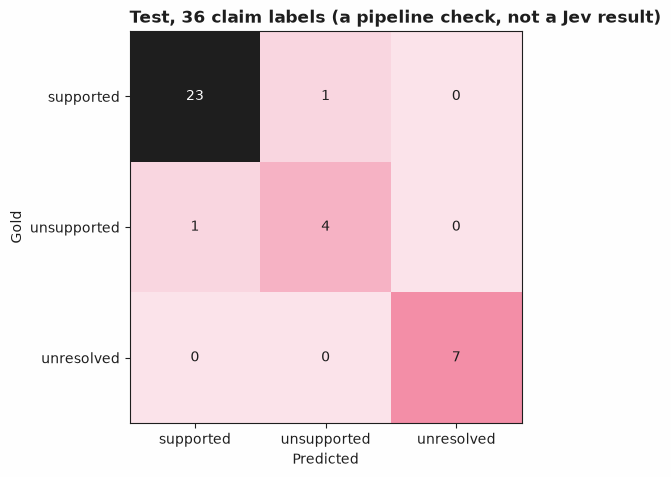

In [9]:
expected = [gold[e["id"]]["claims"][claim] for e in test for claim in helpers.CLAIMS]
predicted = [outcomes[e["id"]].claims[claim] for e in test for claim in helpers.CLAIMS]
matrix = confusion_matrix(expected, predicted, labels=("supported", "unsupported", "unresolved"))
print(f"Test N={len(test)} episodes / {len(expected)} claims; rows=gold, columns=predicted{check}")
for label, row in zip(matrix.labels, matrix.matrix.tolist(), strict=True):
    print(f"{label}: {row}{check}")
plot_confusion_matrix(matrix, title=f"Test, {len(expected)} claim labels{check}")

### Errors that survive the gate

The synthetic fixtures deliberately contain a confident false support answer and a confident false alarm. The gate cannot establish truth: a wrong, certain answer can pass. A missing mismatch can leave an incorrect overlay standing; this is why every retained-overlay recommendation is gated and there is no exempt fallback. Review blocks action for a detected contradiction, but it cannot catch a contradiction the semantic answer misses.

In [10]:
for example in test:
    ident = example["id"]
    if outcomes[ident].claims != gold[ident]["claims"]:
        print(f"{ident}: gold={gold[ident]['claims']}; predicted={outcomes[ident].claims}{check}")
        print(f"  recommendation={outcomes[ident].recommendation}; review={outcomes[ident].review}")
print("ActionLog entries are simulated recommendations; executed is always false:")
for action in actions.to_dicts():
    print({key: value for key, value in action.items() if key != "answer"})

t05: gold={'phase': 'supported', 'action': 'supported', 'status': 'supported'}; predicted={'phase': 'supported', 'action': 'supported', 'status': 'unsupported'} (a pipeline check, not a Jev result)
  recommendation=review evidence before any overlay update; review=True
t11: gold={'phase': 'supported', 'action': 'unsupported', 'status': 'supported'}; predicted={'phase': 'supported', 'action': 'supported', 'status': 'supported'} (a pipeline check, not a Jev result)
  recommendation=retain the verified overlay; review=False
ActionLog entries are simulated recommendations; executed is always false:
{'seq': 0, 'kind': 'overlay recommendation', 'payload': {'example': 't01', 'recommendation': 'retain the verified overlay'}, 'step': None, 'rule': 'all claims supported; valid, fresh timestamps', 'executed': False}
{'seq': 1, 'kind': 'overlay recommendation', 'payload': {'example': 't11', 'recommendation': 'retain the verified overlay'}, 'step': None, 'rule': 'all claims supported; valid, fresh 

## What was and was not measured

The cell below prints mode, returned model and capture date when applicable, and N in every mode. Validation is a selection step; only a recorded held-out test run can report sample-specific model results. An unrecorded live run is exploratory and not reportable. The live wrapper measures request elapsed time and retains returned token usage; absent measurements remain null. Cost is not estimated.

Synthetic replay establishes no Jev accuracy, latency, input tokens or cost. `vision.run_record` explicitly leaves all those resource fields null, including the model. These authored diagrams do not represent actual video encoding, clock skew, frame drops, games, streaming platforms, strategic quality or the frequency of failures in a real stream. The timestamp policy cannot detect a frozen image with fresh capture timestamps.

Event accuracy uses every held-out episode, including unresolved and temporal-review cases, with the existing visually established mismatch labels. The measured cell repeats each method's correct count, N and event accuracy; claim abstention above prevents interpreting a negative event label as verified agreement.

In [11]:
print(
    f"Mode={backend.mode}; N={len(validation)} validation, {len(test)} test, {len(demo)} unscored demos{check}"
)
print(f"Test units: {len(test)} episodes; {len(test) * len(helpers.CLAIMS)} claim labels{check}")
if offline:
    print("Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(validation)} validation and {len(test)} test episodes{check}")
else:
    print(f"N: {len(validation)} validation and {len(test)} test episodes")
    returned = sorted({result.model for result in results.values()})
    dates = sorted(
        {
            answer.provenance.date
            for result in results.values()
            for answer in result.answers.values()
        }
    )
    print("Returned models:", returned, "capture dates:", dates)
    if backend.mode == "live":
        print("Unrecorded live run: exploratory only, not reportable model performance.")
print("Per-request accounting (synthetic measurements stay null):")
for ident, row in accounting.items():
    print(ident, json.dumps(row, sort_keys=True))
assert len(results) == len(examples) == 26
assert all(not item["executed"] for item in actions.to_dicts())
for method, report in reports.items():
    event = report["event"]
    print(
        f"{method}: N={event['N']} held-out episodes; event accuracy="
        f"{event['correct']}/{event['N']}={event['accuracy']:.3f}{check}"
    )

Mode=synthetic; N=12 validation, 12 test, 2 unscored demos (a pipeline check, not a Jev result)
Test units: 12 episodes; 36 claim labels (a pipeline check, not a Jev result)
Not measured live: a pipeline check, not a Jev result.
N: 12 validation and 12 test episodes (a pipeline check, not a Jev result)
Per-request accounting (synthetic measurements stay null):
d01 {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens": null}
v01 {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens": null}
v02 {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens": null}
v03 {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens": null}
v04 {"cost_usd": null, "input_tokens": null, "latency_seconds": null, "mode": "synthetic", "model": null, "output_tokens"

## Next steps

Read [tool outcome verification](../29-tool-outcome-verification/) for the difference between a reported success and evidence of success, then [multi-agent task assignment](../49-multi-agent-task-assignment/) for composing judgments with strict Python constraints.

Try new authored validation episodes with independently timestamped telemetry or partial HUD visibility. Freeze any new questions or gates before collecting a fresh test set. If you later study real streams, use licensed material and record the returned model, capture date and measurement provenance. Keep a human review before applying overlay changes.

References: [S02: Primitives](https://docs.typesafe.ai/primitives), [S03: Confidence](https://docs.typesafe.ai/confidence), [S09: Images](https://docs.typesafe.ai/images), [S11: Models](https://docs.typesafe.ai/models), [S12: Jev 1.14 release](https://typesafe.ai/blog/jev-1-14), and the repository's [vision utilities](../../docs/vision.md).